# Predicción de ataque al corazón (Clasificación)

1. Preparación de Datos
2. División de los datos 70-30
3. Aprendizaje del Modelo
4. Evaluación del Modelo: matriz de confusión, P, R, ROC
5. Guardar el modelo

* El despliegue se realiza en `app.py` (Streamlit): `streamlit run app.py`

**Correcciones respecto a la versión anterior**
- Se limpian las comillas de `smoking_status` (`'never smoked'` → `never smoked`).
- Variables categóricas con **dummies** (`get_dummies`) en lugar de un único `LabelEncoder` reutilizado
  (el encoder de las X se sobrescribía y no se podía reproducir en el despliegue; además `smoking_status`
  es nominal y codificarla 0,1,2,3 inventa un orden).
- El `MinMaxScaler` se ajusta **solo con el 70% de entrenamiento** (antes con el 100% → fuga de información)
  y se aplica **una sola vez** (antes se normalizaba dos veces los mismos datos).
- Datos **desbalanceados** (~5% "Yes"): se usa `class_weight='balanced'` y se evalúa con sensibilidad (recall) y AUC,
  no solo con exactitud (un modelo que dice siempre "No" ya tiene 95% de exactitud).
- Semilla fija (`random_state`) para que los resultados sean reproducibles.
- El modelo final se entrena con el 100% de los datos **ya codificados** (antes daba `ValueError`).

In [1]:
#Importamos librerías básicas
import pandas as pd # manipulacion dataframes
import numpy as np  # matrices y vectores
import matplotlib.pyplot as plt #gráfica
from sklearn import metrics

# 1. Preparación de Datos

In [2]:
#Cargamos los datos
data = pd.read_excel("ataque_corazon.xlsx", sheet_name="Datos")
data.head()

,age,hypertension,heart_disease,ever_married,avg_glucose_level,smoking_status,stroke_ataque_corazon
0,1,No,No,No,122.04,Unknown,No
1,79,No,No,Yes,79.03,Unknown,No
2,40,No,No,Yes,60.96,'never smoked',No
3,4,No,No,No,107.25,Unknown,No
4,8,No,No,No,106.51,Unknown,No


In [3]:
#Limpieza: smoking_status trae comillas simples en algunas categorías
data['smoking_status'] = data['smoking_status'].str.strip("'")
for col in data.select_dtypes(include='object').columns:
    print(col, data[col].unique())
print("\nValores nulos:", data.isna().sum().sum())
data['stroke_ataque_corazon'].value_counts(normalize=True)

hypertension ['No' 'Yes']
heart_disease ['No' 'Yes']
ever_married ['No' 'Yes']
smoking_status ['Unknown' 'never smoked' 'formerly smoked' 'smokes']
stroke_ataque_corazon ['No' 'Yes']

Valores nulos: 0


stroke_ataque_corazon
No     0.951272
Yes    0.048728
Name: proportion, dtype: float64

In [4]:
#Variables dummies para las predictoras categóricas (drop_first evita columnas redundantes)
from sklearn.preprocessing import LabelEncoder

X = data.drop("stroke_ataque_corazon", axis=1) # Variables predictoras
X = pd.get_dummies(X, drop_first=True, dtype=int)

#Codificar la variable objetivo: No -> 0, Yes -> 1
labelencoder = LabelEncoder()
Y = labelencoder.fit_transform(data['stroke_ataque_corazon']) #Variable objetivo
print(labelencoder.classes_)
X.head()

['No' 'Yes']


,age,avg_glucose_level,hypertension_Yes,heart_disease_Yes,ever_married_Yes,smoking_status_formerly smoked,smoking_status_never smoked,smoking_status_smokes
0,1,122.04,0,0,0,0,0,0
1,79,79.03,0,0,1,0,0,0
2,40,60.96,0,0,1,0,1,0
3,4,107.25,0,0,0,0,0,0
4,8,106.51,0,0,0,0,0,0


# 2. División 70-30

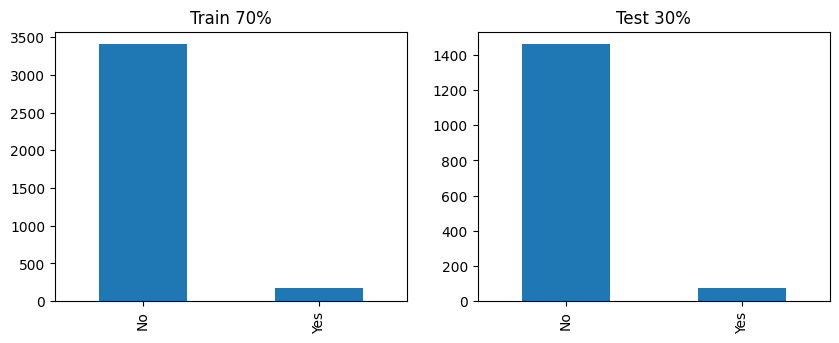

In [5]:
#División 70-30
from sklearn.model_selection import train_test_split
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.3, stratify=Y, random_state=42) #Muestreo estratificado

fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
pd.Series(labelencoder.inverse_transform(Y_train)).value_counts().plot(kind='bar', ax=ax[0], title='Train 70%')
pd.Series(labelencoder.inverse_transform(Y_test)).value_counts().plot(kind='bar', ax=ax[1], title='Test 30%')
plt.show()

# 3. Aprendizaje con el 70% y Evaluación con el 30%

Función de evaluación común: matriz de confusión, reporte (P, R, F1) y curva ROC.

In [6]:
resultados = {}

def evaluar(nombre, modelo, X_eval, Y_eval):
    Y_pred = modelo.predict(X_eval)
    Y_prob = modelo.predict_proba(X_eval)[:, 1]

    fig, ax = plt.subplots(1, 2, figsize=(11, 4))
    metrics.ConfusionMatrixDisplay.from_predictions(Y_eval, Y_pred, display_labels=labelencoder.classes_, ax=ax[0])
    metrics.RocCurveDisplay.from_predictions(Y_eval, Y_prob, ax=ax[1], name=nombre)
    ax[0].set_title(nombre)
    plt.show()

    print(metrics.classification_report(Y_eval, Y_pred, target_names=labelencoder.classes_, zero_division=0))
    resultados[nombre] = {
        'accuracy': metrics.accuracy_score(Y_eval, Y_pred),
        'balanced_accuracy': metrics.balanced_accuracy_score(Y_eval, Y_pred),
        'recall_yes': metrics.recall_score(Y_eval, Y_pred),
        'precision_yes': metrics.precision_score(Y_eval, Y_pred, zero_division=0),
        'f1_yes': metrics.f1_score(Y_eval, Y_pred),
        'auc': metrics.roc_auc_score(Y_eval, Y_prob),
    }

# **Tree**
No se normaliza

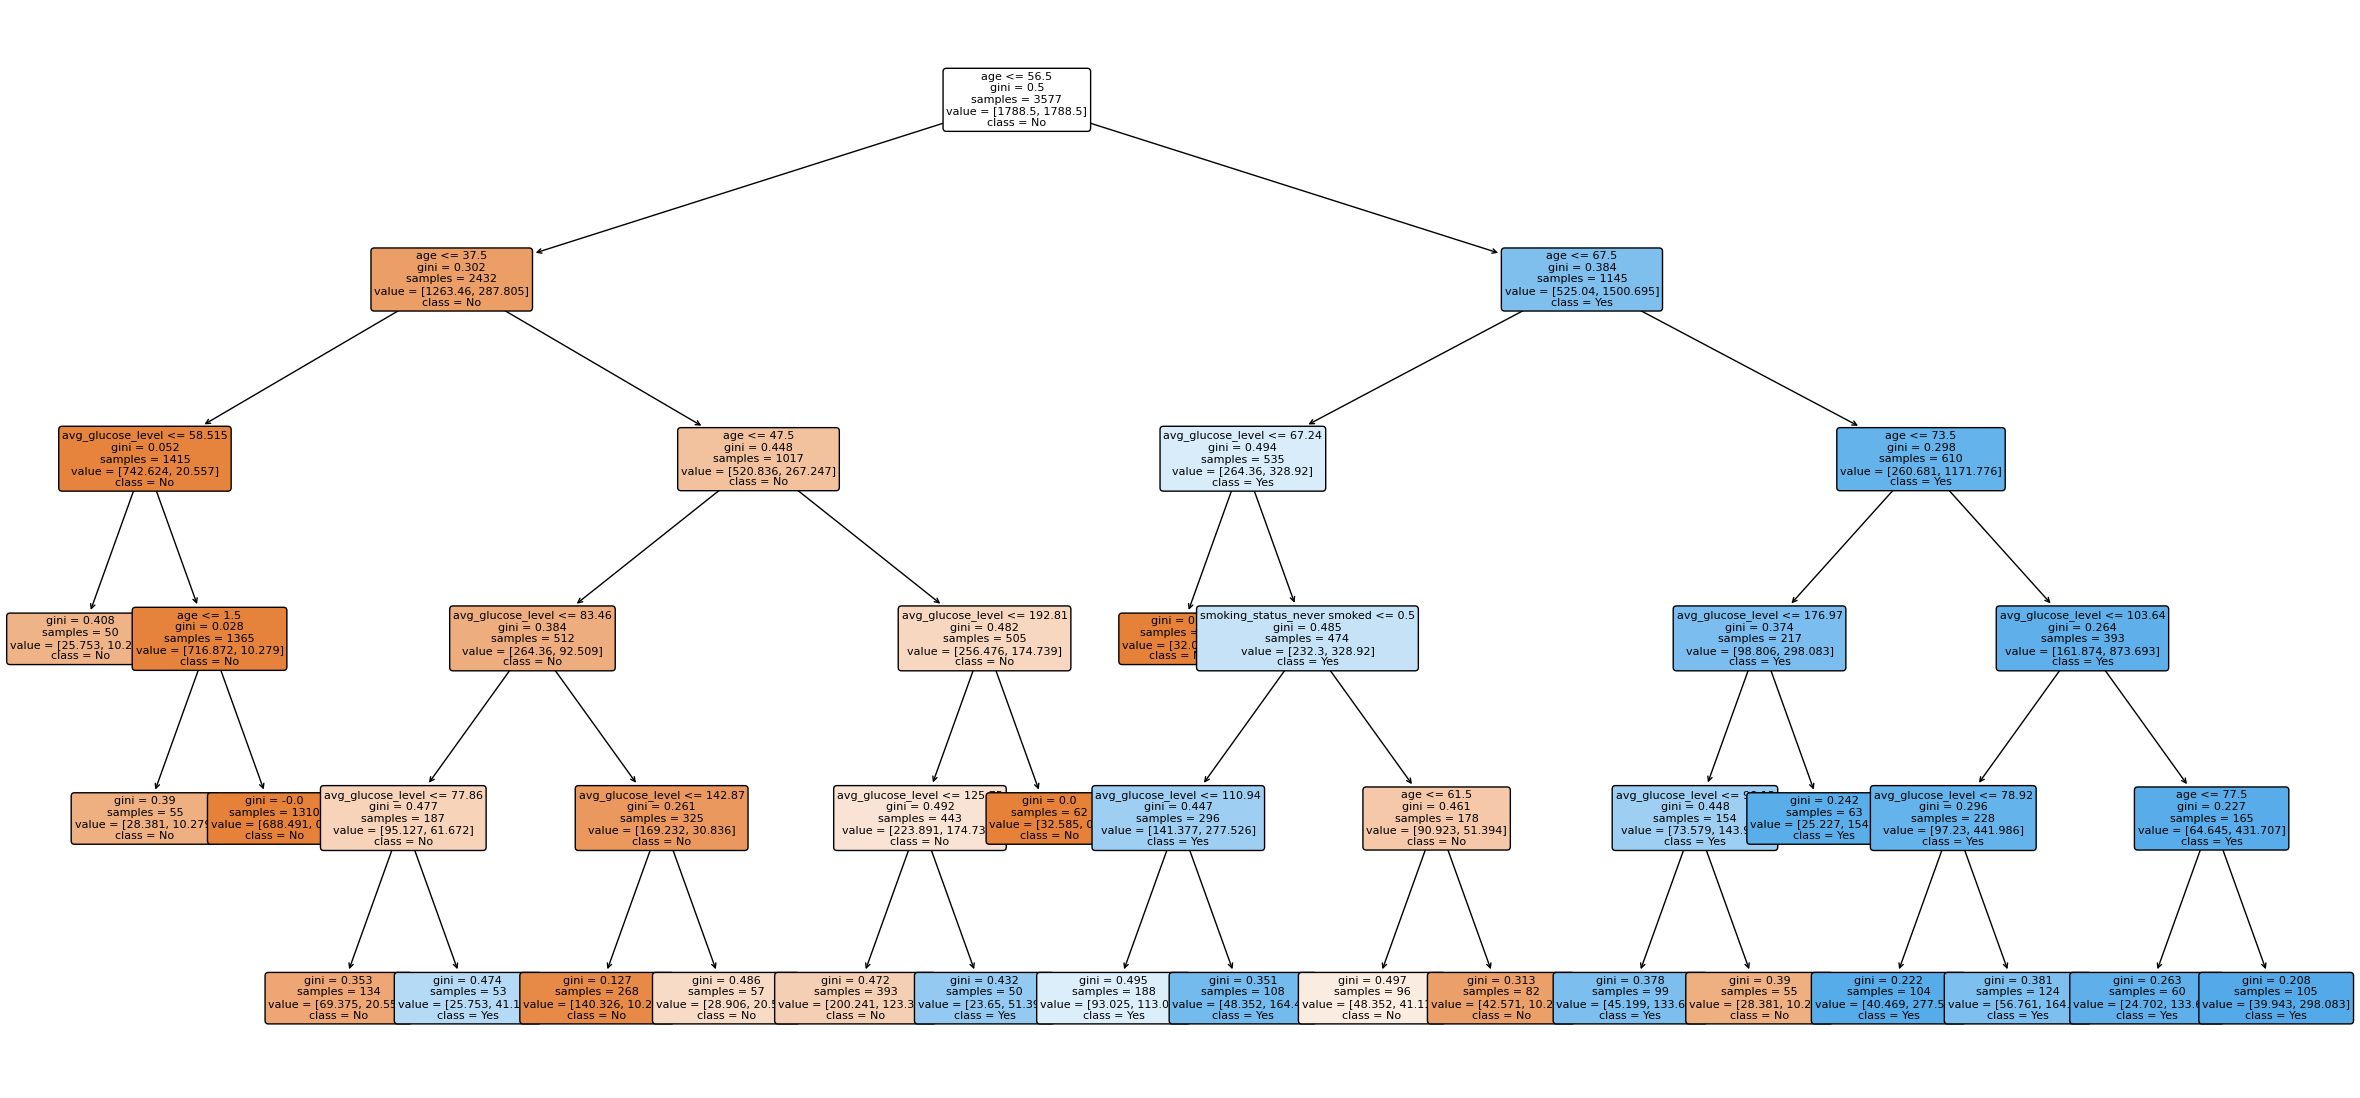

In [7]:
#Creación del modelo con el conjunto de entrenamiento
from sklearn.tree import DecisionTreeClassifier, plot_tree

modelTree = DecisionTreeClassifier(criterion='gini', min_samples_leaf=50, max_depth=5,
                                   class_weight='balanced', random_state=42) #balanced: compensa el desbalance
modelTree.fit(X_train, Y_train) #70% train

plt.figure(figsize=(30,14))
plot_tree(modelTree, feature_names=X_train.columns.values, class_names=labelencoder.classes_, rounded=True, fontsize=8, filled=True)
plt.show()

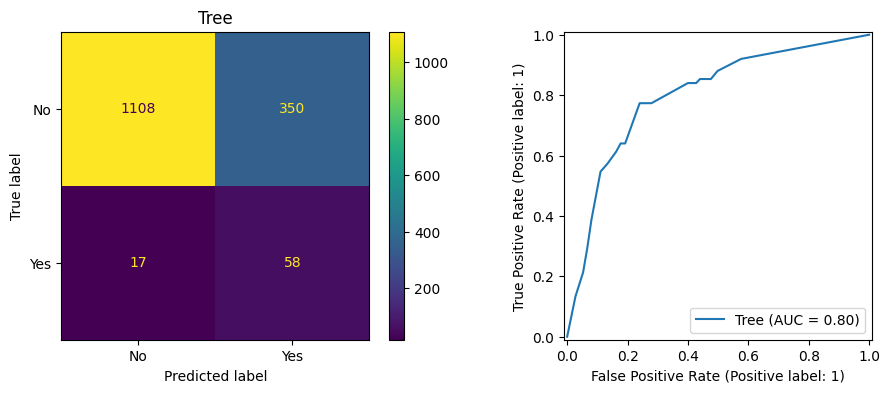

              precision    recall  f1-score   support

          No       0.98      0.76      0.86      1458
         Yes       0.14      0.77      0.24        75

    accuracy                           0.76      1533
   macro avg       0.56      0.77      0.55      1533
weighted avg       0.94      0.76      0.83      1533



In [8]:
evaluar("Tree", modelTree, X_test, Y_test)

# Normalización (para KNN, Red Neuronal, SVM y Regresión Logística)
* Se ajusta solo con el 70% de entrenamiento y se aplica **una sola vez**.
* Las dummies no se normalizan.

In [9]:
from sklearn.preprocessing import MinMaxScaler

variables_numericas = ['age', 'avg_glucose_level']
min_max_scaler = MinMaxScaler()
min_max_scaler.fit(X_train[variables_numericas]) #Ajuste de min - max solo con el 70%

X_train_n = X_train.copy()
X_test_n = X_test.copy()
X_train_n[variables_numericas] = min_max_scaler.transform(X_train[variables_numericas]) #70%
X_test_n[variables_numericas] = min_max_scaler.transform(X_test[variables_numericas])   #30%
X_train_n.describe().loc[['min', 'max']]

,age,avg_glucose_level,hypertension_Yes,heart_disease_Yes,ever_married_Yes,smoking_status_formerly smoked,smoking_status_never smoked,smoking_status_smokes
min,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
max,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0


# **KNN**
* `n_neighbors=1` sobreajusta (memoriza); se usa un vecindario mayor.
* KNN no admite pesos de clase: con 5% de positivos rara vez llega a predecir "Yes".

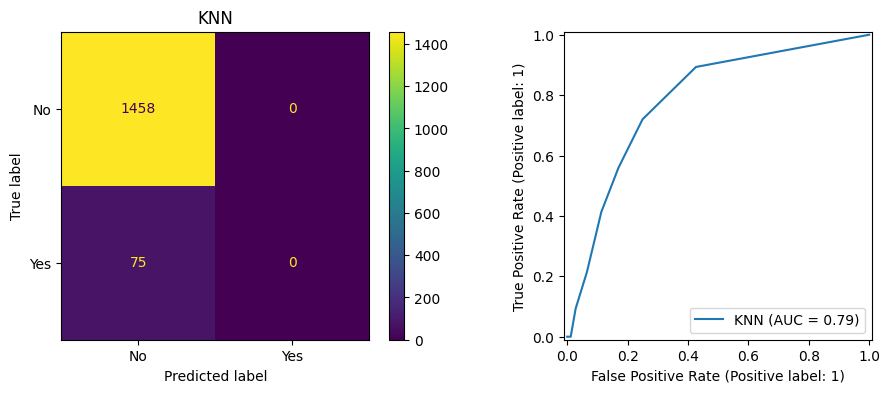

              precision    recall  f1-score   support

          No       0.95      1.00      0.97      1458
         Yes       0.00      0.00      0.00        75

    accuracy                           0.95      1533
   macro avg       0.48      0.50      0.49      1533
weighted avg       0.90      0.95      0.93      1533



In [10]:
from sklearn.neighbors import KNeighborsClassifier

modelKnn = KNeighborsClassifier(n_neighbors=25, metric='euclidean')
modelKnn.fit(X_train_n, Y_train) #70%
evaluar("KNN", modelKnn, X_test_n, Y_test)

# **Red Neuronal**
* `MLPClassifier` no admite `class_weight`, por eso con el umbral 0.5 no detecta casos positivos.

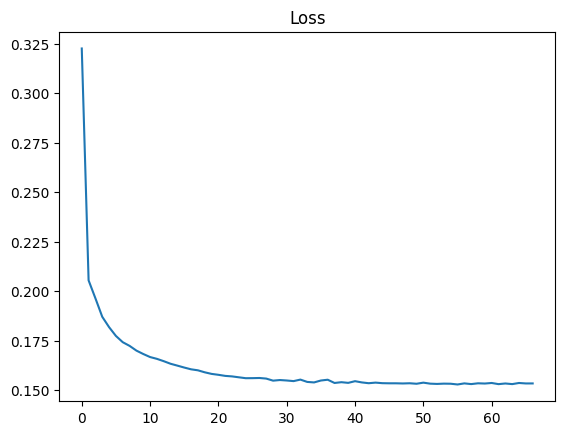

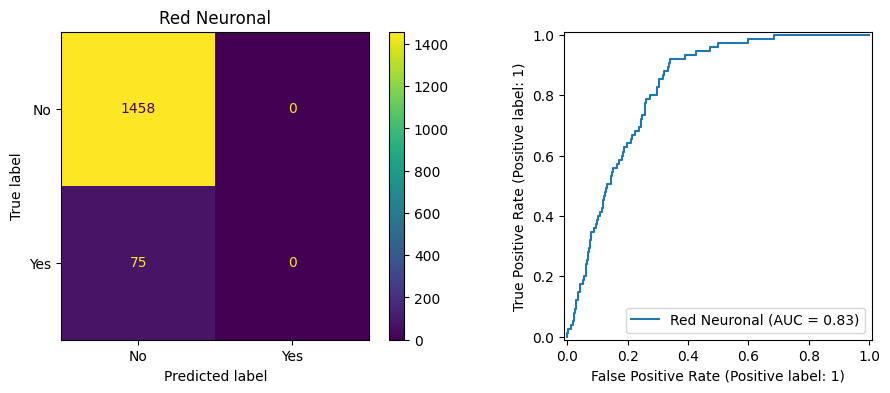

              precision    recall  f1-score   support

          No       0.95      1.00      0.97      1458
         Yes       0.00      0.00      0.00        75

    accuracy                           0.95      1533
   macro avg       0.48      0.50      0.49      1533
weighted avg       0.90      0.95      0.93      1533



In [11]:
from sklearn.neural_network import MLPClassifier

modelNN = MLPClassifier(activation="logistic", hidden_layer_sizes=(15,), learning_rate='constant',
                        learning_rate_init=0.02, momentum=0.03, max_iter=500, random_state=3)
modelNN.fit(X_train_n, Y_train) #70% normalizados
plt.plot(modelNN.loss_curve_); plt.title('Loss'); plt.show()
evaluar("Red Neuronal", modelNN, X_test_n, Y_test)

# **SVM**

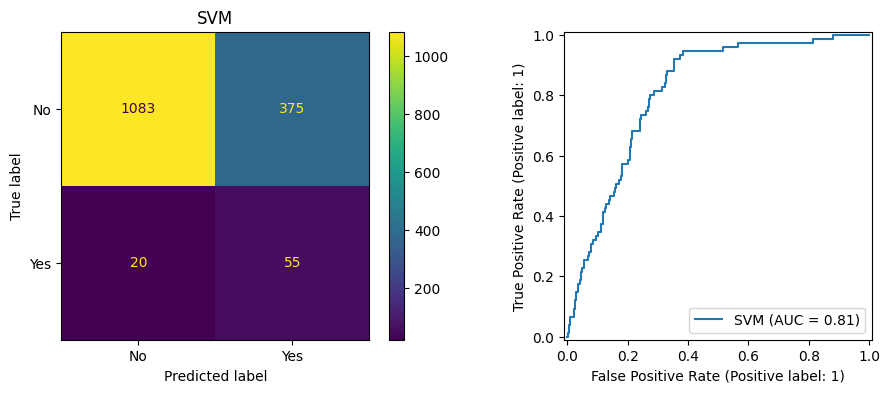

              precision    recall  f1-score   support

          No       0.98      0.74      0.85      1458
         Yes       0.13      0.73      0.22        75

    accuracy                           0.74      1533
   macro avg       0.55      0.74      0.53      1533
weighted avg       0.94      0.74      0.82      1533



In [12]:
from sklearn.svm import SVC

modelSVM = SVC(kernel='rbf', C=1, class_weight="balanced", probability=True, random_state=42) #probability para ROC/AUC
modelSVM.fit(X_train_n, Y_train) #70%
evaluar("SVM", modelSVM, X_test_n, Y_test)

# **Regresión Logística**

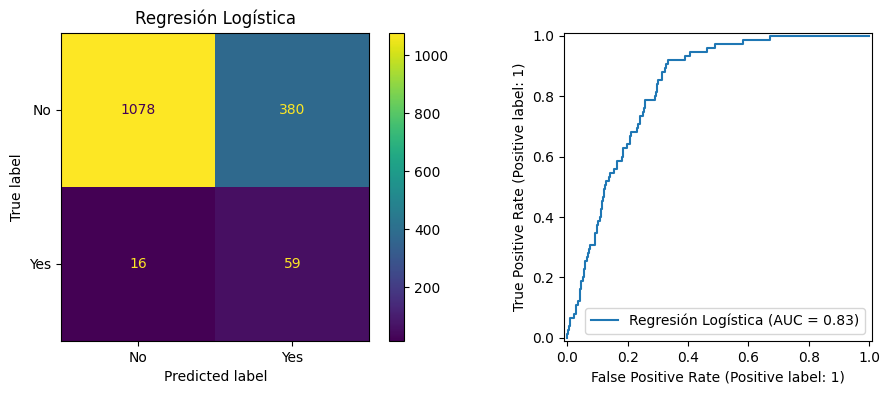

              precision    recall  f1-score   support

          No       0.99      0.74      0.84      1458
         Yes       0.13      0.79      0.23        75

    accuracy                           0.74      1533
   macro avg       0.56      0.76      0.54      1533
weighted avg       0.94      0.74      0.81      1533



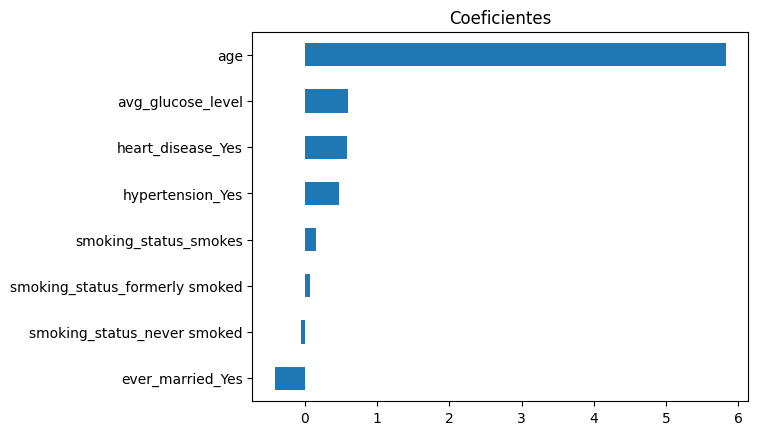

In [13]:
from sklearn.linear_model import LogisticRegression

modelLR = LogisticRegression(class_weight='balanced', max_iter=1000, random_state=3)
modelLR.fit(X_train_n, Y_train) # 70% normalizados
evaluar("Regresión Logística", modelLR, X_test_n, Y_test)

pd.Series(modelLR.coef_[0], index=X_train_n.columns).sort_values().plot(kind='barh', title='Coeficientes')
plt.show()

# 4. Comparación de modelos
Con datos desbalanceados la **exactitud engaña**: decir siempre "No" da ~95%.
Se priorizan **AUC** y **sensibilidad (recall de "Yes")**, porque no detectar un paciente en riesgo es el error más costoso.

In [14]:
comparacion = pd.DataFrame(resultados).T.sort_values('auc', ascending=False)
comparacion.style.format('{:.3f}').background_gradient(cmap='Greens', subset=['auc', 'recall_yes', 'balanced_accuracy'])

,accuracy,balanced_accuracy,recall_yes,precision_yes,f1_yes,auc
Regresión Logística,0.742,0.763,0.787,0.134,0.230,0.828
Red Neuronal,0.951,0.500,0.000,0.000,0.000,0.825
SVM,0.742,0.738,0.733,0.128,0.218,0.812
Tree,0.761,0.767,0.773,0.142,0.240,0.800
KNN,0.951,0.500,0.000,0.000,0.000,0.786


# 5. Guardamos el mejor modelo (primero por calidad y segundo por complejidad computacional)
**Regresión Logística**: mejor AUC y sensibilidad, y es el modelo más simple e interpretable.

Se entrena el modelo final con el 100% de los datos (X, Y), normalizando X con un scaler ajustado al 100%.

In [15]:
#Normalizar X (100% de los datos) - necesario para Knn, NN, SVM, Reg. Si fuese Tree no se normaliza.
min_max_scaler = MinMaxScaler()
X_n = X.copy()
X_n[variables_numericas] = min_max_scaler.fit_transform(X[variables_numericas])

#Entrenamos modelo final
modelFinal = LogisticRegression(class_weight='balanced', max_iter=1000, random_state=3)
modelFinal.fit(X_n, Y) #100%

LogisticRegression(class_weight='balanced', max_iter=1000, random_state=3)

In [16]:
import pickle, json
filename = 'modelo-class.pkl'
variables = X.columns.values
pickle.dump([modelFinal, labelencoder, variables, min_max_scaler], open(filename, 'wb'))

#Metadatos para el despliegue (métricas del 30% de prueba)
info = {'modelo': 'Regresión Logística (class_weight=balanced)', 'umbral': 0.5, 'n_registros': len(data),
        'metricas_test': {k: round(float(v), 4) for k, v in resultados['Regresión Logística'].items()}}
json.dump(info, open('modelo-info.json', 'w', encoding='utf-8'), ensure_ascii=False, indent=2)
print(variables)

['age' 'avg_glucose_level' 'hypertension_Yes' 'heart_disease_Yes'
 'ever_married_Yes' 'smoking_status_formerly smoked'
 'smoking_status_never smoked' 'smoking_status_smokes']


# Prueba del modelo guardado
Se simula el despliegue: se carga el `.pkl` y se predice la hoja *Predicciones futuras* aplicando la misma preparación.

In [17]:
model, le, variables, scaler = pickle.load(open('modelo-class.pkl', 'rb'))

nuevos = pd.read_excel("ataque_corazon.xlsx", sheet_name="Predicciones futuras")
nuevos['smoking_status'] = nuevos['smoking_status'].str.strip("'")
Xn = pd.get_dummies(nuevos, dtype=int).reindex(columns=variables, fill_value=0) #mismas columnas que en entrenamiento
Xn[variables_numericas] = scaler.transform(Xn[variables_numericas])

nuevos['probabilidad'] = model.predict_proba(Xn)[:, 1]
nuevos['prediccion'] = le.inverse_transform(model.predict(Xn))
nuevos

,age,hypertension,heart_disease,ever_married,avg_glucose_level,smoking_status,probabilidad,prediccion
0,81,No,No,Yes,81.95,never smoked,0.765708,Yes
1,60,Yes,No,Yes,213.03,smokes,0.765162,Yes
2,79,No,No,Yes,79.03,Unknown,0.789472,Yes
